In [62]:
%load_ext autoreload
%autoreload 2

from src.DicomRTHandler import DicomRTHandler
from src.config_presets.tools.load_config import load_config
import numpy as np

config = load_config('HNC/UMCG_data.yaml')


ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\CT"
rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTDOSE\IM1.DCM"
rtstruct_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT\RS1.2.752.243.1.1.20220324125917617.1240.35401.dcm"
CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT"

# # directories of the CT, rtdose and rtstruct dicom files
# ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\CT"
# rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTDOSE\IM1.DCM"
# CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT"

# # folder of deep learning contours (if applicable)
DLC_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\DLC\9296488\no_contrast\RTSTRUCT"
# #DLC_RTSTRUCT_DIR = None

# # # # contrast
# ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\with_contrast\CT"
# # no contrast
# #ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\no_contrast\20180716\CT"
# rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\no_contrast\20180716\RTDOSE\RTDOSE_1.2.752.243.1.1.20180725161405473.2160.62180.dcm"
# CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\no_contrast\20180716\RTSTRUCT"
# DLC_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\DLC\0059896\no_contrast\RTSTRUCT"

# # # # # # contrast
ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\with_contrast\CT"
# no contrast
#ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\CT"
rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTDOSE\IM1.DCM"
CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTSTRUCT"
DLC_RTSTRUCT_DIR = None

# enable and disable verbose print statements (mostly used for debugging)
VERBOSE = True

handler = DicomRTHandler(config, verbose=VERBOSE)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
src\config_presets\HNC/UMCG_data.yaml


In [63]:
# Load data 

# # load the CT files
handler.load_ct_series(ct_folder)

# # load the RTDOSE file, and resample it to the CT grid
handler.load_rtdose(rtdose_file)

# load the available RTSTRUCT files (loops through a folder of DICOM files)
handler.load_rtstructs(CITOR_RTSTRUCT_DIR, DLC_folder_dir = DLC_RTSTRUCT_DIR, fix_uids=True)
# If no DLCs, then:
# handler.load_rtstructs(CITOR_RTSTRUCT_DIR, fix_uids=False)




# Print summary
#handler.print_summary()


Loading CT series from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\with_contrast\CT...
Loading RTDOSE from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTDOSE\IM1.DCM...
Loading RTSTRUCT from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTSTRUCT...
Loading RTSTRUCT from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTSTRUCT...
  Checking file: \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTSTRUCT\IM1 (1).DCM...
Removed ROIs: ['External', 'BODY', 'Internal5', 'A_Carotid_L', 'A_Carotid_R', 'Arytenoid_L', 'BrainStem', 'Cerebellum', 'Cerebrum', 'SpinalCord', 'Arytenoid_R', 'Eye_Post_L', 'Eye_Post_R', 'Eye_Ant_L', 'Eye_Ant_R', 'BaseOfTongue', '11-21', '1

In [65]:
len(handler.structure_masks_dict)

28

In [51]:
# prints some (very basic) metadata about the loaded data
handler.print_summary()


DICOM RT DATA SUMMARY

CT Series:
  PatientID: 9980149
  ScanDate: 20200108
  Manufacturer: SIEMENS
  ModelName: SOMATOM Definition AS
  KiloVoltPeak: 100.0
  ImageOrientationPatient: [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0, 0, 1]
  ImagePositionPatient: [-249.51171875, -473.51171875, -210.0]
  Spacing: [0.9765625, 0.9765625]
  RescaleSlope: 1.0
  RescaleIntercept: -1024.0
  SliceThickness: 2.0

RT Dose:
  Matrix: (512, 512, 211)
  Spacing (z,y,x): (0.9765625, 0.9765625, 2.0) mm
  Origin: (-249.51171875, -473.51171875, -210.0) mm


In [52]:
mean_OAR_doses_dict = handler.compute_structure_mean_doses_and_volumes(dose_units='Gy')


Structure mean doses and volumes:
  pcm_inf: mean dose = 0.10 Gy, volume = 5.60 cm3
  OralCavity_Ext_Out: mean dose = 6.65 Gy, volume = 85.44 cm3
  Esophagus_Cerv_Out: mean dose = 0.01 Gy, volume = 4.11 cm3
  esophagus_cerv: mean dose = 0.01 Gy, volume = 4.11 cm3
  Submandibular_R_Out: mean dose = 0.04 Gy, volume = 11.04 cm3
  thyroid: mean dose = 0.04 Gy, volume = 3.03 cm3
  Parotid_L_Out: mean dose = 1.29 Gy, volume = 47.78 cm3
  parotis_re: mean dose = 0.03 Gy, volume = 44.21 cm3
  PCM_Med_Out: mean dose = 3.57 Gy, volume = 4.06 cm3
  submandibularis_li: mean dose = 23.31 Gy, volume = 10.92 cm3
  buccalmucosa_li: mean dose = 38.38 Gy, volume = 9.22 cm3
  submandibularis_re: mean dose = 0.04 Gy, volume = 11.05 cm3
  GlotticArea_Out: mean dose = 0.07 Gy, volume = 3.28 cm3
  pcm_sup: mean dose = 29.13 Gy, volume = 9.52 cm3
  crico: mean dose = 0.03 Gy, volume = 4.80 cm3
  pcm_med: mean dose = 3.72 Gy, volume = 4.08 cm3
  Parotid_R_Out: mean dose = 0.03 Gy, volume = 44.20 cm3
  Crico_O

# Prepare dataset for DL models:

In [53]:
import SimpleITK as sitk

from src.preprocessing.main import preprocess_numpy_data



preprocessed_CT, preprocessed_RTSTRUCT, preprocessed_RTDOSE = preprocess_numpy_data(config, handler)


  - Segmentation shape: (211, 512, 512)
  - Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
  - Background voxels: 55133522
  - Structure voxels: 178862
 -- applying spacing correction --
   Original spacing: (0.9765625, 0.9765625, 2.0)
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
   Corrected spacing: (1.0, 1.0, 2.0)
OARs in z direction: ['parotis_li', 'parotis_re', 'crico', 'thyroid', 'mandible']
OAR values in z direction: [1, 2, 5, 6, 7]
upper_coord: 135, lower_coord: 63
OARs in x direction: ['parotis_li', 'parotis_re']
OAR values in x direction: [1, 2]
upper_coord: 243, lower_coord: 189
OARs in y direction: ['parotis_li', 'parotis_re', 'submandibularis_li', 'submandibularis_re']
OAR values in y direction: [1, 2, 3, 4]
upper_coord: 335, lower_coord: 172


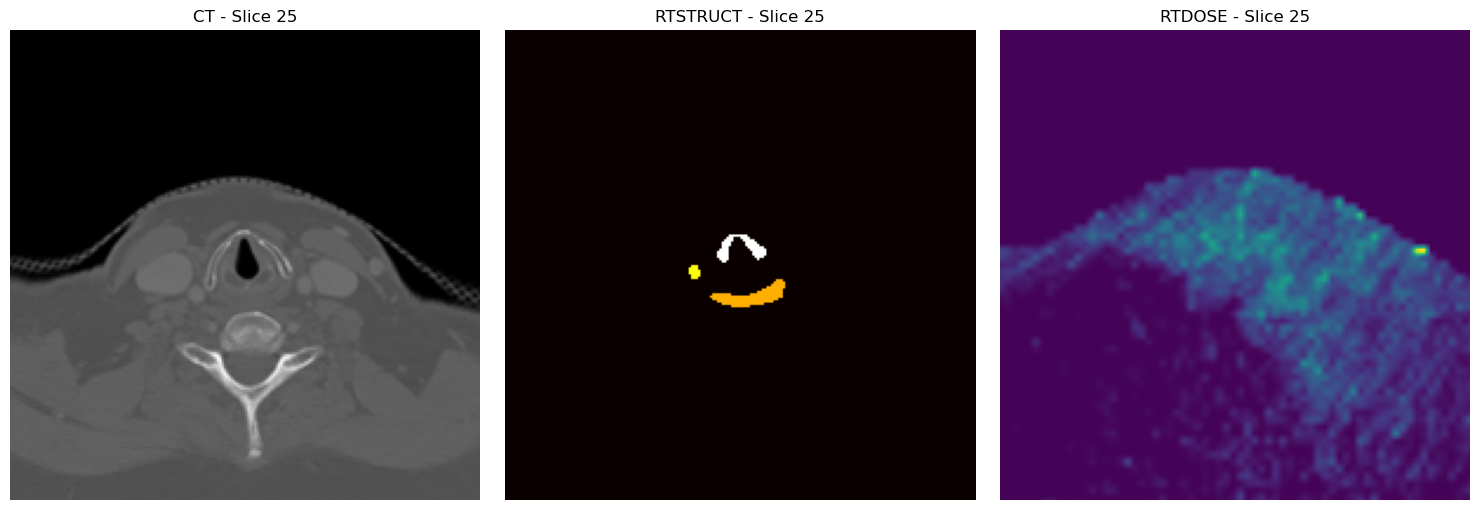

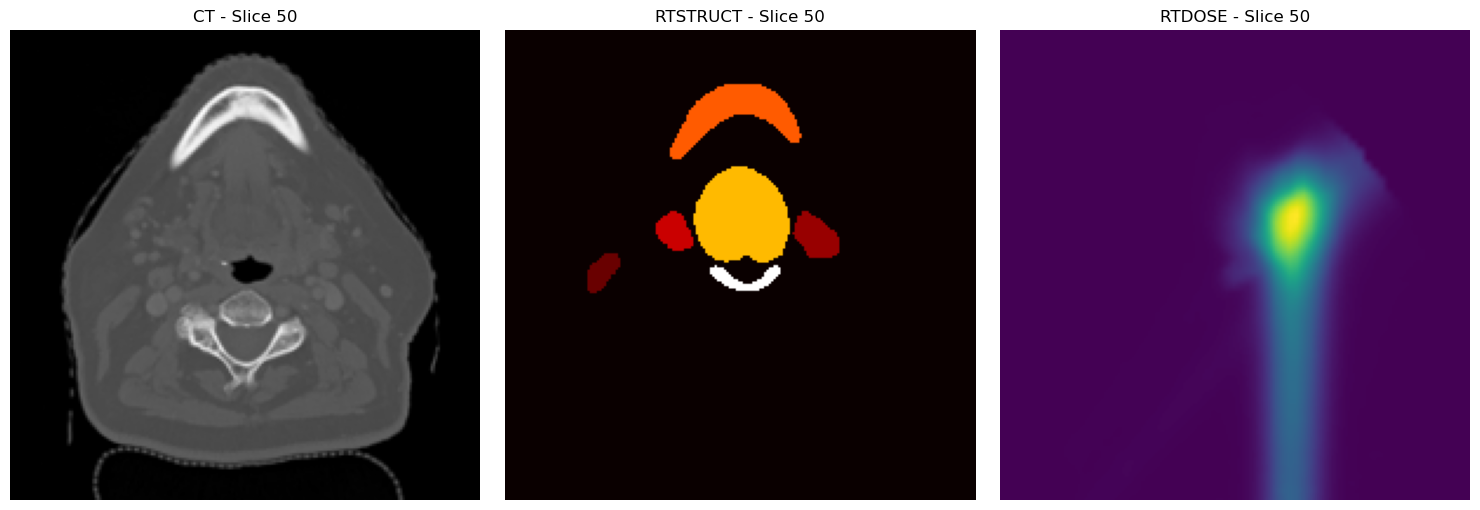

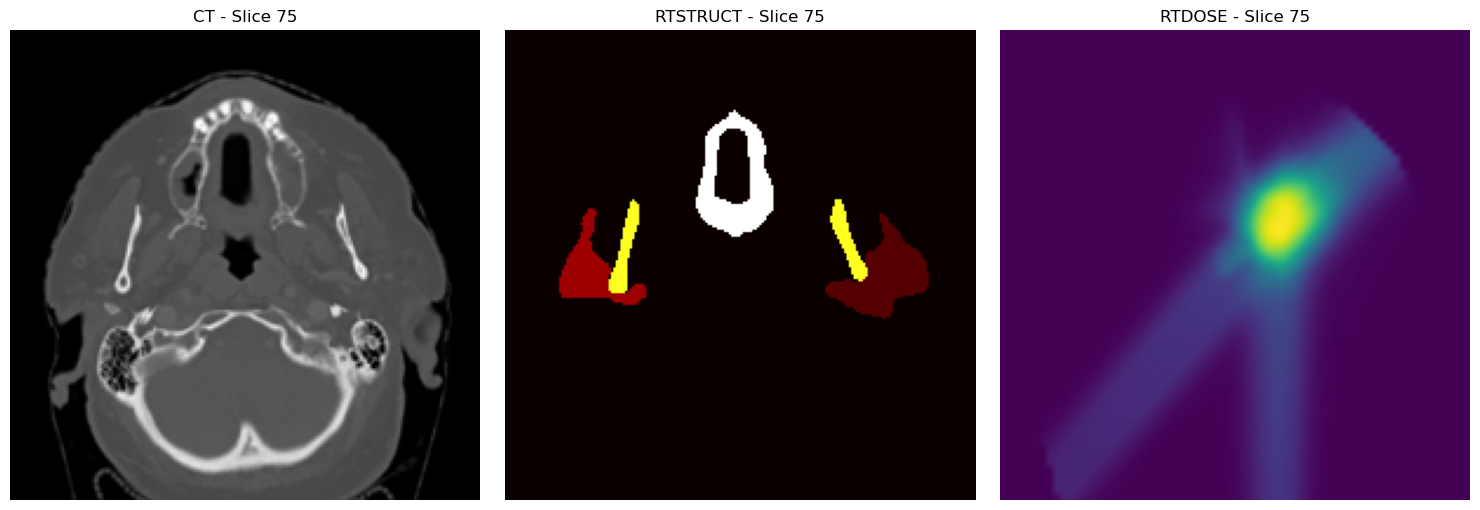

In [54]:
import matplotlib.pyplot as plt

# Select a few slices to visualize
slices = [preprocessed_CT.shape[0] // 4, preprocessed_CT.shape[0] // 2, 3 * preprocessed_CT.shape[0] // 4]

for slice_idx in slices:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Plot CT
    axes[0].imshow(preprocessed_CT[slice_idx], cmap='gray')
    axes[0].set_title(f'CT - Slice {slice_idx}')
    axes[0].axis('off')
    
    # Plot RTSTRUCT
    axes[1].imshow(preprocessed_RTSTRUCT[slice_idx], cmap='hot')
    axes[1].set_title(f'RTSTRUCT - Slice {slice_idx}')
    axes[1].axis('off')
    
    # Plot RTDOSE
    axes[2].imshow(preprocessed_RTDOSE[slice_idx], cmap='viridis')
    axes[2].set_title(f'RTDOSE - Slice {slice_idx}')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

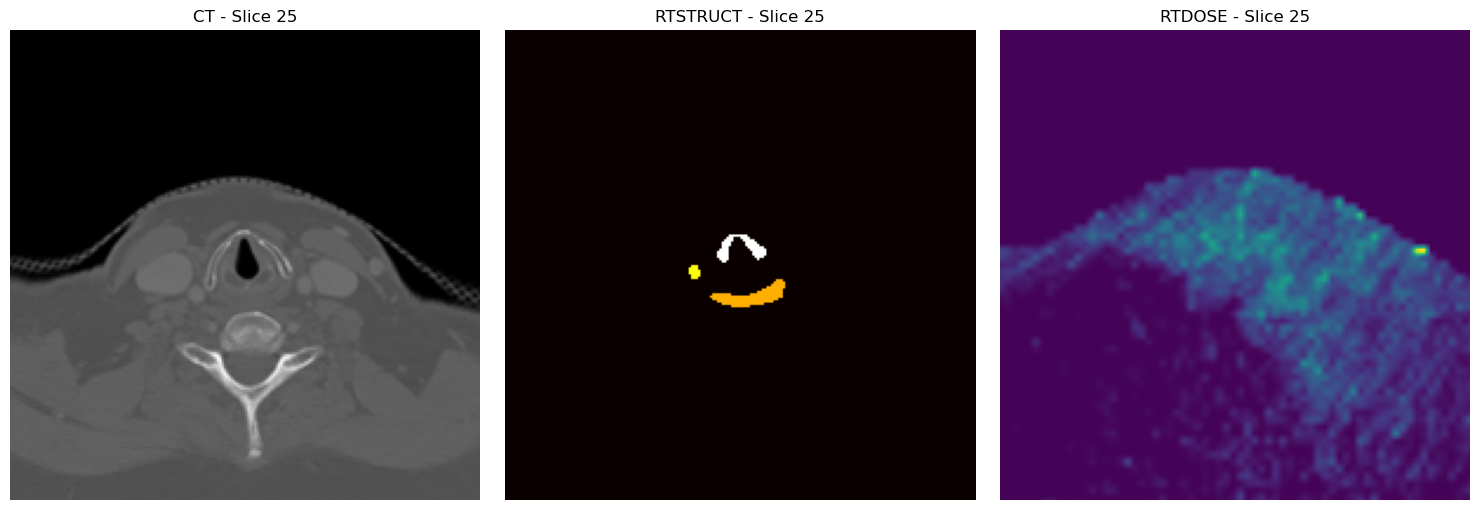

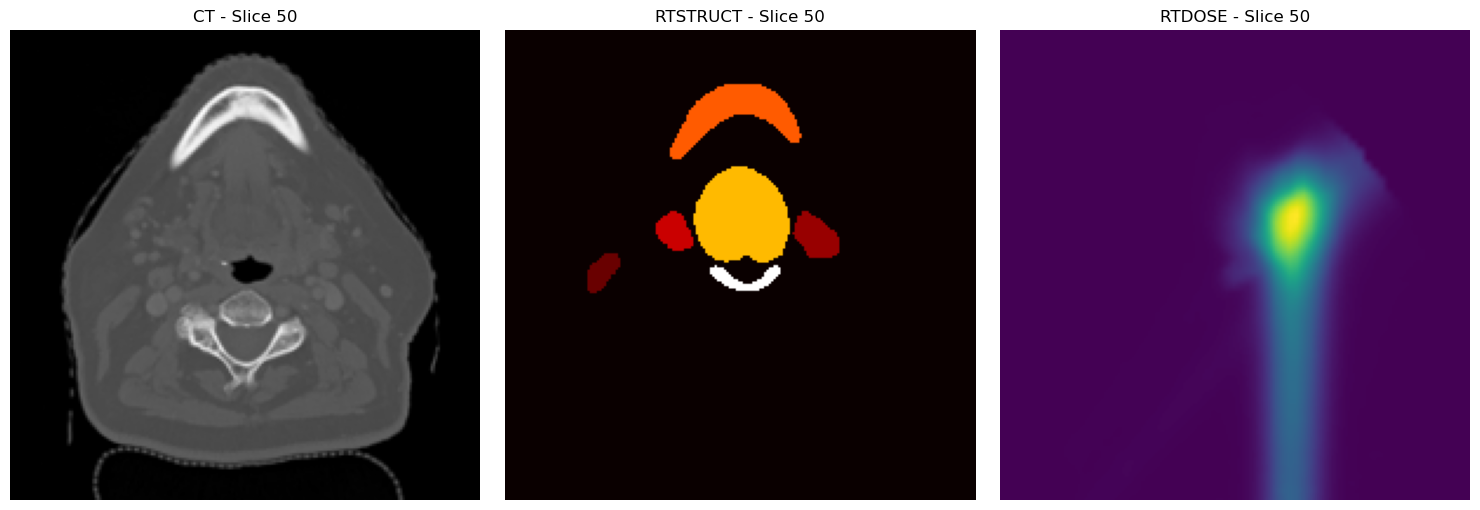

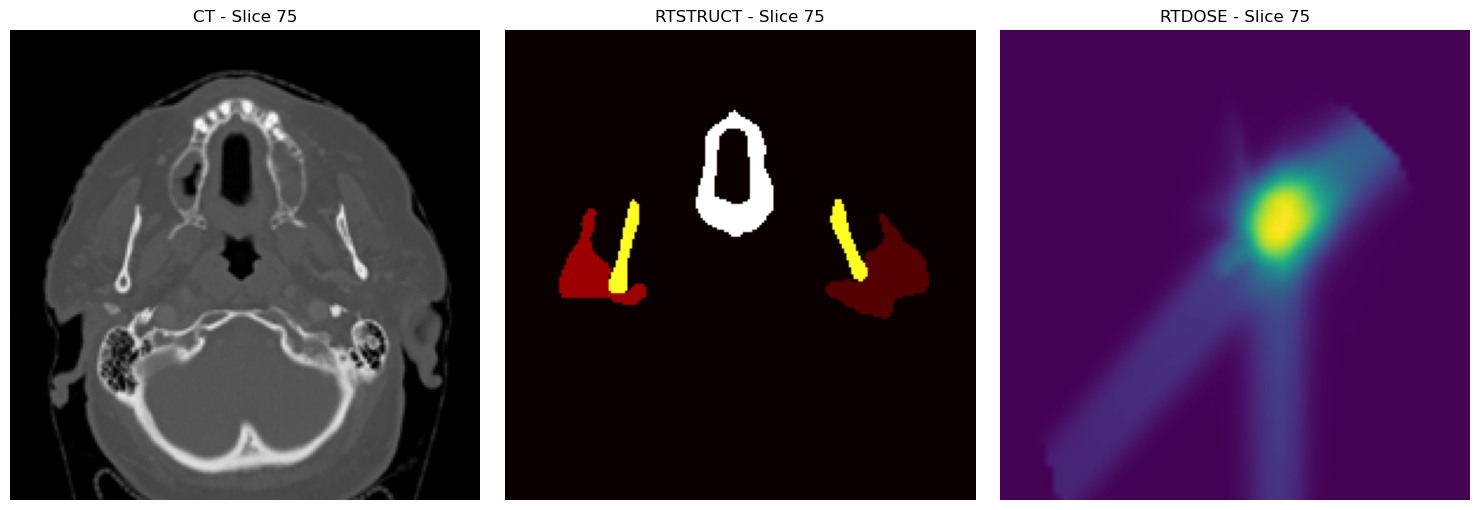

In [28]:
import matplotlib.pyplot as plt

# Select a few slices to visualize
slices = [preprocessed_CT.shape[0] // 4, preprocessed_CT.shape[0] // 2, 3 * preprocessed_CT.shape[0] // 4]

for slice_idx in slices:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Plot CT
    axes[0].imshow(preprocessed_CT[slice_idx], cmap='gray')
    axes[0].set_title(f'CT - Slice {slice_idx}')
    axes[0].axis('off')
    
    # Plot RTSTRUCT
    axes[1].imshow(preprocessed_RTSTRUCT[slice_idx], cmap='hot')
    axes[1].set_title(f'RTSTRUCT - Slice {slice_idx}')
    axes[1].axis('off')
    
    # Plot RTDOSE
    axes[2].imshow(preprocessed_RTDOSE[slice_idx], cmap='viridis')
    axes[2].set_title(f'RTDOSE - Slice {slice_idx}')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()